# Formatting changes to time point-specific reference pathway overlaps - September 9, 2017

In [1]:
%matplotlib inline
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import seaborn as sns
import pandas as pd
import os

# Enlarge the text labels
sns.set_context('paper', font_scale=1.5)
sns.set_style('whitegrid')

eval_dir = os.path.join('..','..','evaluation','2016-07-02-overlap-analysis')
in_file = os.path.join(eval_dir, 'overlap-analysis-with-ratios.tsv')
out_file = os.path.join(eval_dir, 'overlap-analysis-with-ratios-formatted.tsv')
out_fig = os.path.join(eval_dir, 'overlap-analysis-with-ratios')

## Format the axis to show percentages
From PhosphoPathwayCoverage080315.ipynb

In [2]:
def to_percent(y, position):
    # Ignore the passed in position. This has the effect of scaling the default
    # tick locations.
    s = str(int(round(100 * y)))

    # The percent symbol needs escaping in latex
    if mpl.rcParams['text.usetex'] == True:
        return s + r'$\%$'
    else:
        return s + '%'

# Create the formatter using the function to_percent. This multiplies all the
# default labels by 100, making them all percentages
formatter = FuncFormatter(to_percent)

## Read the input table
Use different header names

In [3]:
header = ['Reference', 'Time (min)', 'Phosphorylated proteins count', 'Phosphorylated proteins on pathway count', 'Phosphorylated proteins on pathway']
eval_df = pd.read_csv(in_file, sep='\t', names = header, header = 0)
print 'Loaded %d pathway overlap rows' % len(eval_df)
assert len(eval_df) == 7 * 12
eval_df.head()

Loaded 84 pathway overlap rows


,Reference,Time (min),Phosphorylated proteins count,Phosphorylated proteins on pathway count,Phosphorylated proteins on pathway
0,biocarta-edges.tsv,2min,68,21,0.308824
1,biocarta-edges.tsv,4min,97,20,0.206186
2,biocarta-edges.tsv,8min,63,12,0.190476
3,biocarta-edges.tsv,16min,34,10,0.294118
4,biocarta-edges.tsv,32min,28,5,0.178571


## Test derived column

In [4]:
for (index, row) in eval_df.iterrows():
    assert abs(row['Phosphorylated proteins on pathway'] - float(row['Phosphorylated proteins on pathway count'])/float(row['Phosphorylated proteins count'])) < 0.0001, row

## Rename pathways
Drop the Panther evaluation. We did not use it when evaluating phosphorylation overlap.  Use the same pathway names used in the phoshorylation overlap figures.

Remove 'min' from the time points.

In [5]:
# Remove the Panther rows
eval_df = eval_df.loc[eval_df['Reference'] != 'panther-edges.tsv']

# Map the pathway names to human-readable names
pathway_names = {'kegg-4012':'KEGG ErbB', # http://www.genome.jp/kegg-bin/show_pathway?hsa04012
                    'kegg-4010':'KEGG MAPK', # http://www.genome.jp/kegg-bin/show_pathway?hsa04010
                    'layek':'Layek et al.', # http://bioinformatics.oxfordjournals.org/content/27/4/548/F4.large.jpg
                    'reactome-reactome-egfr':'Reactome EGFR',
                    'biocarta-egfr':'BioCarta EGF', # http://www.biocarta.com/pathfiles/h_egfpathway.asp
                    'science-signaling-egfr':'Science Signaling EGFR', # Not longer available online
                    'cellmap-commons-egfr':'Cancer Cell Map EGFR1', # http://www.pathwaycommons.org/pc/dbSnapshot.do?snapshot_id=8
                    'nci-nature-egfr':'PID ErbB1', # http://pid.nci.nih.gov/search/pathway_landing.shtml?pathway_id=200101&source=NATURE&what=graphic&jpg=on
                    'biocarta':'All BioCarta',
                    'reactome-reactome':'All Reactome',
                    'nci-nature':'All PID'}
print '%d reference pathways' % len(pathway_names)

# Rename the reference pathway column
eval_df.insert(0, 'Reference pathway', eval_df.apply(lambda row: pathway_names[row['Reference'].replace('-edges.tsv', '')], axis=1))
eval_df = eval_df.drop('Reference', axis=1)

# Rename the times
eval_df['Time (min)'] = eval_df.apply(lambda row: row['Time (min)'].replace('min', ''), axis=1)

# Confirm the expected number of rows remain
times = len(eval_df['Time (min)'].unique())
assert len(eval_df) == times * len(pathway_names)

eval_df.head()

11 reference pathways


,Reference pathway,Time (min),Phosphorylated proteins count,Phosphorylated proteins on pathway count,Phosphorylated proteins on pathway
0,All BioCarta,2,68,21,0.308824
1,All BioCarta,4,97,20,0.206186
2,All BioCarta,8,63,12,0.190476
3,All BioCarta,16,34,10,0.294118
4,All BioCarta,32,28,5,0.178571


## Write the updated table

In [6]:
eval_df.to_csv(out_file, sep='\t', index=False)
print 'Wrote %s' % out_file

Wrote ..\..\evaluation\2016-07-02-overlap-analysis\overlap-analysis-with-ratios-formatted.tsv


## Plot the time-specific overlaps

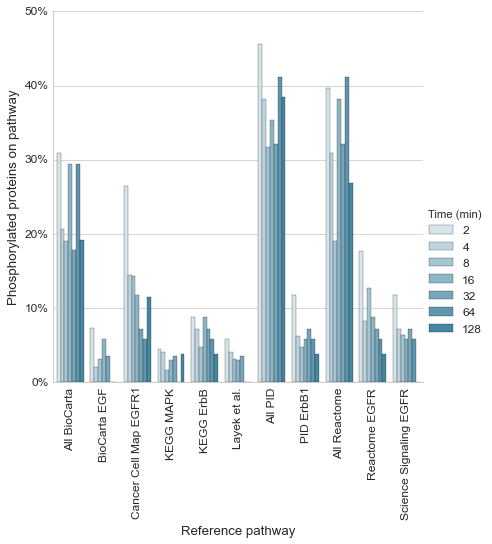

In [7]:
plt.figure();
# Add an extra color to skip over the lightest color
pal = sns.light_palette((230,85,55), n_colors=times+1, input='husl');
pal = pal[1:];
# Returns a FacetGrid object
grid = sns.factorplot(x='Reference pathway', y='Phosphorylated proteins on pathway', hue='Time (min)', data=eval_df, size=6, kind='bar', palette=pal);
# Format the y-axis labels as percents, get the axis from the FacetGrid
grid.ax.yaxis.set_major_formatter(formatter)
plt.xticks(rotation=90);

plt.savefig(out_fig + '.png', dpi=600, bbox_inches='tight')
plt.savefig(out_fig + '.svg', bbox_inches='tight')